$$
(\frac{dr}{d\phi})^2 = \frac{r^4}{b^2} - r^2(1-\frac{2M}{r})
$$

Fazendo $u(\phi) = \frac{1}{r(\phi)}$
$$

$$

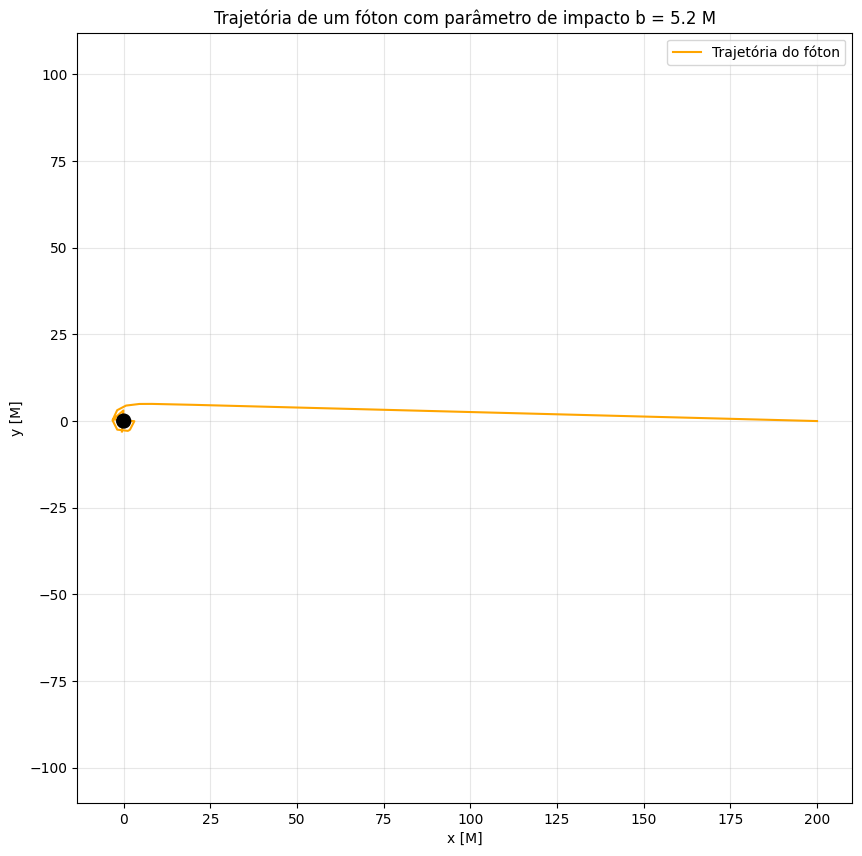

In [37]:
import numpy as np
from scipy.integrate import solve_ivp
import matplotlib.pyplot as plt

# Parâmetros do buraco negro
M = 1.0  # Massa em unidades geometrizadas
b = 5.2  # Parâmetro de impacto (b > 3√3 M ≈ 5.196 para escape)

# Condições iniciais: fóton começa à direita no eixo x
r_init = 200.0  # Distância inicial
phi_init = 0.0   # Ângulo inicial (sobre o eixo x)

# Sistema de equações para geodésica nula
def geodesic(lambda_, y):
    r, phi = y
    # Expressão dentro da raiz quadrada
    inside = 1 - (1 - 2*M/r) * b**2 / r**2
    if inside < 0:
        drdlambda = 0  # Caso não físico, mas evita erro numérico
    else:
        drdlambda = -np.sqrt(inside)  # Negativo para fóton se aproximando
    dphidlambda = b / r**2
    return [drdlambda, dphidlambda]

# Função de evento para detectar ponto de retorno (onde dr/dλ = 0)
def event_turning(lambda_, y):
    r = y[0]
    return 1 - (1 - 2*M/r) * b**2 / r**2
event_turning.terminal = True  # Interrompe a integração no evento
event_turning.direction = -1   # Detecta transição de positivo para negativo

# Integração da parte inicial (approximation)
N = 1000
sol1 = solve_ivp(geodesic, [0, N], [r_init, phi_init], events=event_turning, dense_output=True)

# Ponto de retorno
r_turn = sol1.y[0][-1]
phi_turn = sol1.y[1][-1]

# Sistema para a parte de afastamento (dr/dλ positivo)
def geodesic_out(lambda_, y):
    r, phi = y
    inside = 1 - (1 - 2*M/r) * b**2 / r**2
    if inside < 0:
        drdlambda = 0
    else:
        drdlambda = np.sqrt(inside)  # Positivo para fóton se afastando
    dphidlambda = b / r**2
    return [drdlambda, dphidlambda]

# Integração da parte de afastamento
sol2 = solve_ivp(geodesic_out, [0, 1000], [r_turn, phi_turn], dense_output=True)

# Combinar as soluções
lambda_vals = np.concatenate([sol1.t, sol1.t[-1] + sol2.t])
r_vals = np.concatenate([sol1.y[0], sol2.y[0]])
phi_vals = np.concatenate([sol1.y[1], sol2.y[1]])

# Converter para coordenadas cartesianas
x = r_vals * np.cos(phi_vals)
y = r_vals * np.sin(phi_vals)

# Plotagem
plt.figure(figsize=(10, 10))
circle = plt.Circle((0, 0), 2*M, color='black', fill=True, zorder=10)
plt.gca().add_patch(circle)
plt.plot(0, 0, 'ko', markersize=3, zorder=11)
plt.plot(x, y, color='orange', label='Trajetória do fóton')
plt.xlabel('x [M]')
plt.ylabel('y [M]')
plt.title(f'Trajetória de um fóton com parâmetro de impacto b = {b} M')
plt.axis('equal')
plt.grid(True, alpha=0.3)
plt.legend()
plt.show()